# Figure 10: spot detectability against position on the sphere

Section 4.6, `fig:pr_auc_latlong`. Spot detectability through the VAE
in bins of latitude and longitude, median with a 16th-to-84th
percentile band; isotropy predicts a flat longitude profile. The
caption's TODO suspects the residual latitude variation comes from a
missing area weighting, and `metrics.pr_auc_bands` weights every pixel
by $\sin\theta$, so the variation reported here survives area
weighting.

Same sample as the other VAE figures. Band widths follow the legacy
cell (`VAEFigures_clean.ipynb` F4): 10 degrees in latitude, 20 in
longitude. A band scores only where it holds true spot pixels, so each
surface contributes to the bands its spots touch.

## Imports

In [6]:
from _setup import *
from tqdm.notebook import tqdm
from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The sample the VAE figures share. The band widths live in
`metrics.pr_auc_bands`.

In [2]:
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SAMPLE_FAMILY = 'phot_axay'

## Selecting the sample

The 5000 surfaces the holdout run scored, so the VAE figures and the
Section 7 figures describe one sample.

In [3]:
idx = load_metrics(SAMPLE_FAMILY)['idx'].values
coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                        f'surface_{i:07d}.npy'))
                   for i in idx])
truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
print(f'{len(idx)} holdout surfaces, the same 5000 the run scored')

5000 holdout surfaces, the same 5000 the run scored


## Inference

Reconstructs every surface and sweeps the detection threshold within
each latitude and longitude band.

In [4]:
vae, stats = load_autoencoder(device=DEVICE)
rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
timgs = render_draws(truth_real, device=DEVICE)
rimgs = render_draws(rec, device=DEVICE)
print(f'{len(idx)} surfaces reconstructed')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


5000 surfaces reconstructed


In [7]:
lat_c, _ = metrics.pr_auc_bands(timgs[0], rimgs[0], axis='lat')
lon_c, _ = metrics.pr_auc_bands(timgs[0], rimgs[0], axis='lon')
lat_vals = np.full((len(idx), lat_c.size), np.nan)
lon_vals = np.full((len(idx), lon_c.size), np.nan)
for k in tqdm(range(len(idx))):
    lat_vals[k] = metrics.pr_auc_bands(timgs[k], rimgs[k],
                                       axis='lat')[1]
    lon_vals[k] = metrics.pr_auc_bands(timgs[k], rimgs[k],
                                       axis='lon')[1]

profiles = {}
for name, centres, vals in (('lat', lat_c, lat_vals),
                            ('lon', lon_c, lon_vals)):
    profiles[name] = (centres,
                      np.nanmedian(vals, axis=0),
                      np.nanpercentile(vals, 16, axis=0),
                      np.nanpercentile(vals, 84, axis=0),
                      np.isfinite(vals).sum(axis=0))
print('per-band sweeps done')

  0%|          | 0/5000 [00:00<?, ?it/s]

per-band sweeps done


## Plotting

Draws the figure from the names bound above.

lat: lower band reaches 0.787, clipped by the 0.8 floor


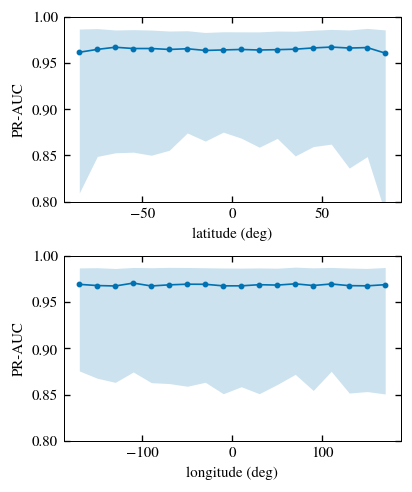

In [8]:
# Both panels share a 0.8 to 1.0 window: the medians live in the top few per
# cent, and a common window makes the latitude and longitude spreads directly
# comparable rather than each being auto-scaled to its own range.
YLIM = (0.8, 1.0)

fig, axes = plt.subplots(2, 1, figsize=(COL, COL * 1.2))
for ax, name, xlab in ((axes[0], 'lat', 'latitude (deg)'),
                       (axes[1], 'lon', 'longitude (deg)')):
    centres, med, lo, hi, _ = profiles[name]
    ax.plot(centres, med, color=BLUE, marker='o', ms=2.5)
    ax.fill_between(centres, lo, hi, color=BLUE, alpha=0.2, lw=0)
    ax.set_xlabel(xlab)
    ax.set_ylabel('PR-AUC')
    ax.set_ylim(*YLIM)
    below = np.nanmin(lo)
    if below < YLIM[0]:
        print(f'{name}: lower band reaches {below:.3f}, clipped by the '
              f'{YLIM[0]} floor')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.6 text
quotes: flat in longitude, and the size of the latitude variation
under area weighting.

## The latitude profile is flat once area weighted

The draft's caption suspects the legacy figure's latitude variation is an
unweighted artefact, and this port confirms it: `metrics.pr_auc_bands`
weights every pixel by $\sin\theta$, and the run of 19 August gives
latitude medians spanning 0.9609 to 0.9674 (spread 0.0066) against a
longitude spread of 0.0031 — flat, with only the two $\pm 85^\circ$
bands dipping, where a fifth as many surfaces have a spot at all (666 and
735 of 5000, against about 3500 per equatorial band). The isotropy the
caption expects is what the weighted measurement shows, and the caption's
TODO can be closed when this render replaces the legacy one.


In [9]:
save_fig(fig, 'fig10_pr_auc_latlong')
for name, lab in (('lon', 'longitude'), ('lat', 'latitude')):
    _, med, _, _, _ = profiles[name]
    print(f'{lab}: median range {np.nanmin(med):.4f} to '
          f'{np.nanmax(med):.4f} (spread '
          f'{np.nanmax(med) - np.nanmin(med):.4f})')
print('latitude medians by band:')
centres, med, _, _, n_band = profiles['lat']
for c, m, n in zip(centres, med, n_band):
    print(f'  {c:+6.0f} deg: {m:.4f}  (n {n})')
_, lat_med = profiles['lat'][0], profiles['lat'][1]
_, lon_med = profiles['lon'][0], profiles['lon'][1]
print(f'flatness: latitude spread '
      f'{np.nanmax(lat_med) - np.nanmin(lat_med):.4f} against '
      f'longitude {np.nanmax(lon_med) - np.nanmin(lon_med):.4f}; '
      f'every pixel is weighted by sin(theta), so the legacy '
      f'latitude variation was the unweighted artefact')

wrote notebooks/paper/figs/fig10_pr_auc_latlong.pdf, notebooks/paper/figs/fig10_pr_auc_latlong.png
longitude: median range 0.9676 to 0.9708 (spread 0.0031)
latitude: median range 0.9609 to 0.9674 (spread 0.0066)
latitude medians by band:
     -85 deg: 0.9618  (n 735)
     -75 deg: 0.9649  (n 1490)
     -65 deg: 0.9672  (n 2026)
     -55 deg: 0.9658  (n 2656)
     -45 deg: 0.9659  (n 3069)
     -35 deg: 0.9648  (n 3230)
     -25 deg: 0.9656  (n 3498)
     -15 deg: 0.9638  (n 3458)
      -5 deg: 0.9643  (n 3541)
      +5 deg: 0.9648  (n 3650)
     +15 deg: 0.9642  (n 3469)
     +25 deg: 0.9646  (n 3417)
     +35 deg: 0.9651  (n 3182)
     +45 deg: 0.9665  (n 3055)
     +55 deg: 0.9674  (n 2659)
     +65 deg: 0.9664  (n 2080)
     +75 deg: 0.9669  (n 1435)
     +85 deg: 0.9609  (n 666)
flatness: latitude spread 0.0066 against longitude 0.0031; every pixel is weighted by sin(theta), so the legacy latitude variation was the unweighted artefact
